# 02 - Exploratory Data Analysis (EDA)
## Prediksi Harga Mobil Bekas di Indonesia

Notebook ini melakukan eksplorasi pola distribusi dan hubungan antarvariabel. Dataset asli tidak diubah pada tahap ini.

**Target:** `price (Rp)`  
**Sumber:** `used_car.csv` dari Kaggle, dataset *Used Car Listings in Indonesia*.

Jalankan setiap cell secara berurutan. Periksa output sebelum menulis interpretasi. Jangan menghapus outlier atau melakukan cleaning pada notebook EDA ini.


## 1. Import Libraries

Library yang digunakan untuk pengolahan data, visualisasi, dan pencarian lokasi file.


In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

RANDOM_STATE = 42
TARGET = "price (Rp)"


## 2. Load Dataset

Notebook ini membaca dataset secara mandiri. Simpan `used_car.csv` di folder `data` pada direktori utama proyek.

Kode mencari file dari direktori kerja notebook maupun direktori induknya. Jika file tidak ditemukan, periksa kembali struktur folder proyek.


In [11]:
candidate_paths = []

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate_paths.append(folder / "data" / "used_car.csv")
    candidate_paths.append(folder / "used_car.csv")

DATA_PATH = next((path.resolve() for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File used_car.csv tidak ditemukan. Letakkan file pada folder "
        "'data' di direktori utama proyek, lalu periksa Path.cwd()."
    )

df = pd.read_csv(DATA_PATH)

print("Lokasi dataset :", DATA_PATH)
print("Dimensi dataset:", df.shape)
display(df.head())


Lokasi dataset : C:\Users\Carbon\OneDrive\Documents\KULIAH UPN\SEMESTER 5\Prak DataScience\project\32_IF-C_bersifatopsional\Data\used_car.csv
Dimensi dataset: (609, 20)


,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
0,AYLA X 1.2,Daihatsu,2018,10.51,Jakarta Utara,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,101000000,2060000
1,AGYA TRD SPORTIVO 1.0,Toyota,2015,112.89,Bogor,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,82000000,1670000
2,X-TRAIL 2.5,Nissan,2015,118.43,Surabaya,Automatic,odd plate,0,0,0,0,0,0,1,0,1,0,0,169000000,3440000
3,YARIS S TRD 1.5,Toyota,2020,15.95,Tangerang Selatan,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,218000000,4440000
4,AGYA G 1.2,Toyota,2019,30.40,Jakarta Barat,Manual,odd plate,0,0,0,0,0,0,0,0,0,0,0,117000000,2380000


In [12]:
print("Informasi struktur dataset:")
df.info()

print("\nJumlah missing value:", int(df.isna().sum().sum()))


Informasi struktur dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car name                   609 non-null    object 
 1   brand                      609 non-null    object 
 2   year                       609 non-null    int64  
 3   mileage (km)               609 non-null    float64
 4   location                   609 non-null    object 
 5   transmission               609 non-null    object 
 6   plate type                 609 non-null    object 
 7   rear camera                609 non-null    int64  
 8   sun roof                   609 non-null    int64  
 9   auto retract mirror        609 non-null    int64  
 10  electric parking brake     609 non-null    int64  
 11  map navigator              609 non-null    int64  
 12  vehicle stability control  609 non-null    int64  
 13  keyless push start    

## 3. Validasi Kolom dan Menyiapkan Variabel Analisis

Validasi ini memastikan kolom utama tersedia. Konversi numerik dilakukan pada Series sementara untuk analisis, bukan menimpa dataset asli.


In [13]:
required_columns = [
    "brand", "year", "mileage (km)", "transmission", TARGET
]

missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise KeyError(f"Kolom yang dibutuhkan tidak ditemukan: {missing_columns}")

price = pd.to_numeric(df[TARGET], errors="coerce")
year = pd.to_numeric(df["year"], errors="coerce")
mileage = pd.to_numeric(df["mileage (km)"], errors="coerce")

print("Jumlah harga yang berhasil dibaca:", int(price.notna().sum()))
print("Jumlah tahun yang berhasil dibaca:", int(year.notna().sum()))
print("Jumlah mileage yang berhasil dibaca:", int(mileage.notna().sum()))

if price.notna().sum() == 0:
    raise ValueError("Kolom target harga tidak berisi nilai numerik yang dapat dianalisis.")


Jumlah harga yang berhasil dibaca: 609
Jumlah tahun yang berhasil dibaca: 609
Jumlah mileage yang berhasil dibaca: 609


## 4. Distribusi Harga Mobil

Analisis meliputi histogram, KDE, boxplot, skewness, dan batas outlier berbasis IQR. Batas IQR digunakan untuk menandai observasi yang perlu diperiksa, bukan sebagai keputusan otomatis untuk menghapus data.


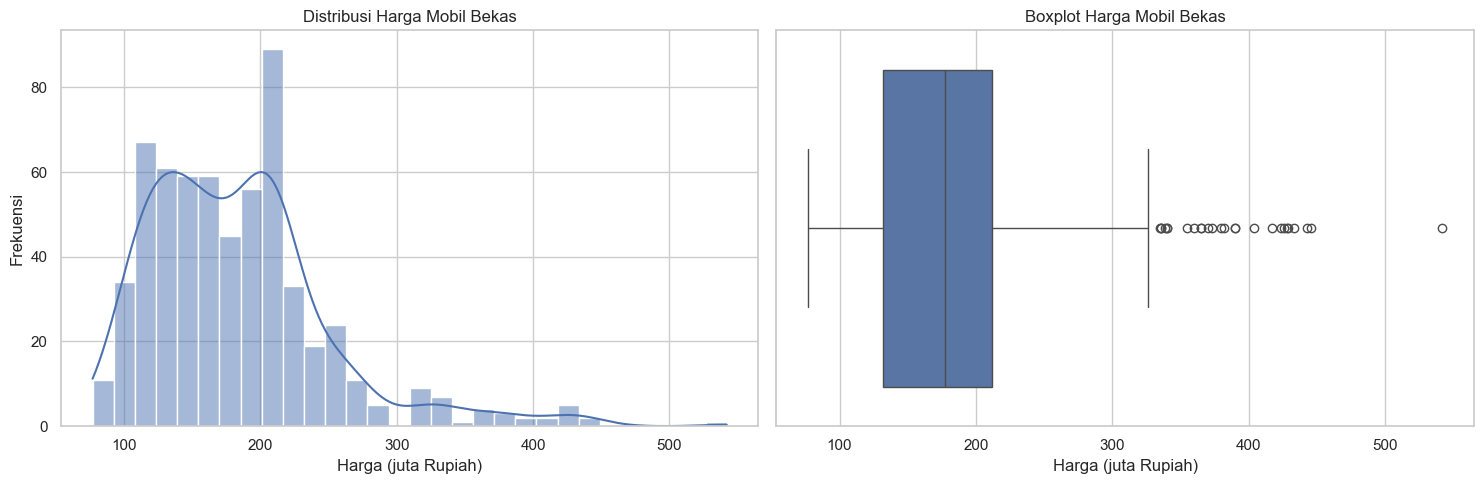

Skewness harga       : 1.452
Q1                   : Rp132,000,000
Median               : Rp177,000,000
Q3                   : Rp212,000,000
IQR                  : Rp80,000,000
Batas bawah IQR      : Rp12,000,000
Batas atas IQR       : Rp332,000,000
Jumlah flag IQR      : 26
Persentase flag IQR  : 4.27%


In [14]:
price_million = price / 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(price_million.dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Harga Mobil Bekas")
axes[0].set_xlabel("Harga (juta Rupiah)")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(x=price_million, ax=axes[1])
axes[1].set_title("Boxplot Harga Mobil Bekas")
axes[1].set_xlabel("Harga (juta Rupiah)")

plt.tight_layout()
plt.show()

price_skewness = price.skew()
q1_price = price.quantile(0.25)
q3_price = price.quantile(0.75)
iqr_price = q3_price - q1_price
lower_price = q1_price - 1.5 * iqr_price
upper_price = q3_price + 1.5 * iqr_price

price_outlier_mask = price.notna() & (
    (price < lower_price) | (price > upper_price)
)

print(f"Skewness harga       : {price_skewness:.3f}")
print(f"Q1                   : Rp{q1_price:,.0f}")
print(f"Median               : Rp{price.median():,.0f}")
print(f"Q3                   : Rp{q3_price:,.0f}")
print(f"IQR                  : Rp{iqr_price:,.0f}")
print(f"Batas bawah IQR      : Rp{lower_price:,.0f}")
print(f"Batas atas IQR       : Rp{upper_price:,.0f}")
print(f"Jumlah flag IQR      : {int(price_outlier_mask.sum())}")
print(f"Persentase flag IQR  : {price_outlier_mask.mean() * 100:.2f}%")


## 5. Distribusi Tahun Produksi

Gunakan histogram untuk melihat konsentrasi tahun produksi dan boxplot untuk memeriksa rentang serta nilai yang berpotensi ekstrem.


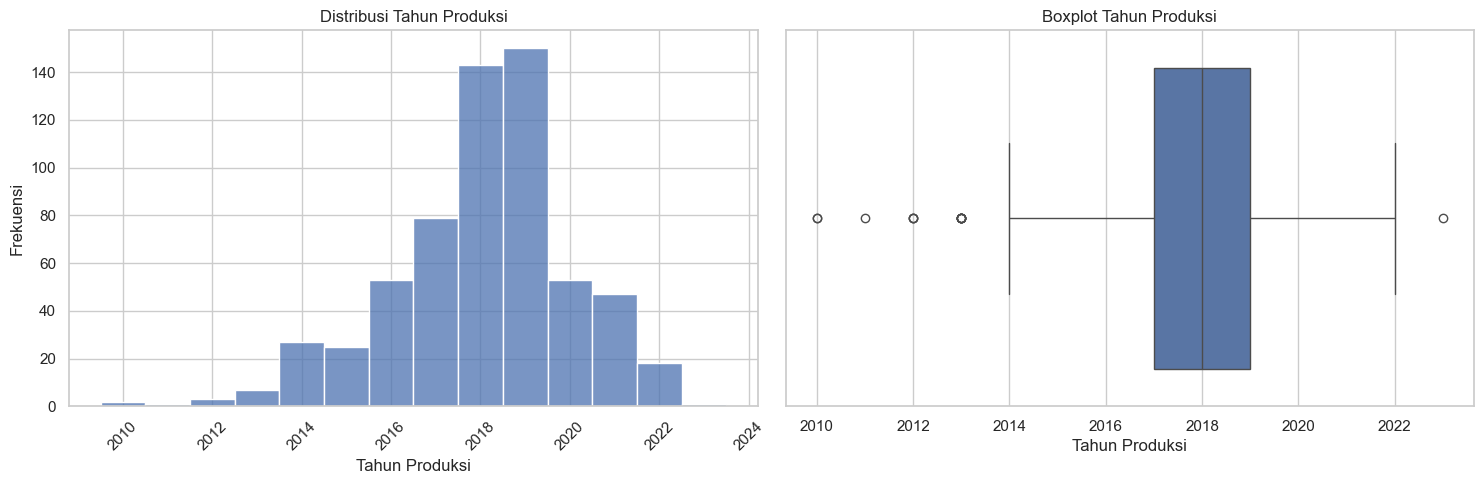

,Statistik Tahun Produksi
count,609.00
mean,"2,018.05"
std,2.03
min,"2,010.00"
25%,"2,017.00"
50%,"2,018.00"
75%,"2,019.00"
max,"2,023.00"


In [15]:
year_valid = year.dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(year_valid, bins=max(5, min(20, year_valid.nunique())), discrete=True, ax=axes[0])
axes[0].set_title("Distribusi Tahun Produksi")
axes[0].set_xlabel("Tahun Produksi")
axes[0].set_ylabel("Frekuensi")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(x=year_valid, ax=axes[1])
axes[1].set_title("Boxplot Tahun Produksi")
axes[1].set_xlabel("Tahun Produksi")

plt.tight_layout()
plt.show()

display(
    year_valid.describe().to_frame("Statistik Tahun Produksi")
)


## 6. Distribusi Mileage

Grafik menggunakan nilai sebagaimana tersimpan pada CSV. Jangan mengubah titik menjadi pemisah ribuan atau desimal dan jangan melakukan konversi satuan sebelum format sumber dikonfirmasi.


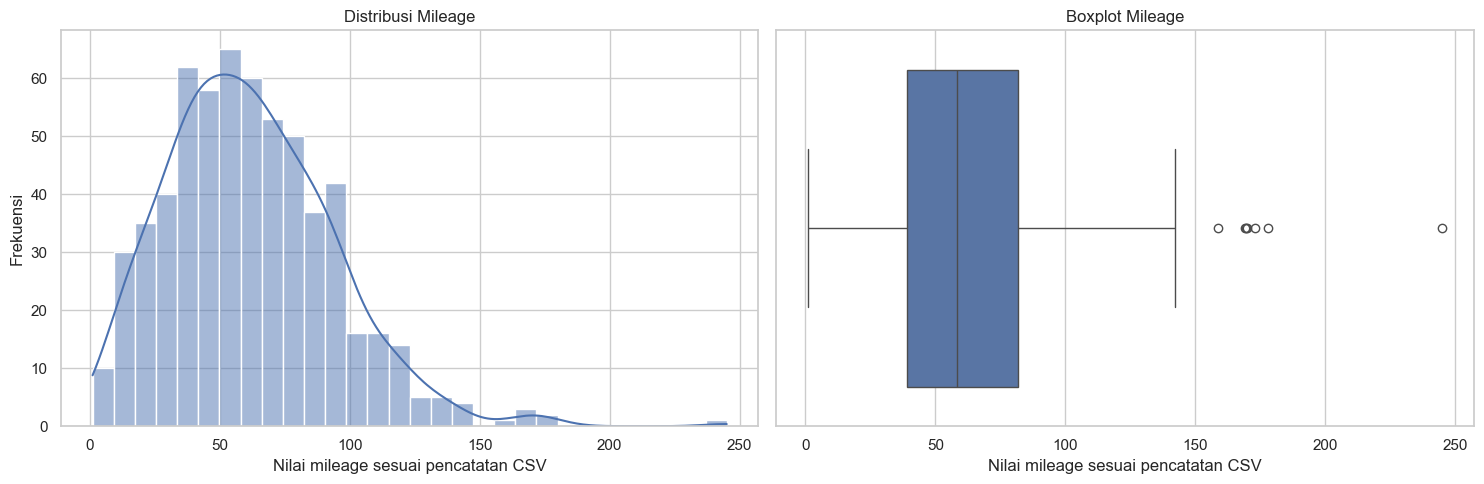

,Statistik Mileage
count,609.00
mean,61.69
std,32.15
min,1.06
25%,39.15
50%,58.37
75%,81.73
max,245.00



Contoh nilai mileage sebagaimana tersimpan:


,mileage (km)
0,10.51
1,112.89
2,118.43
3,15.95
4,30.40
5,17.31
6,12.21
7,126.89
8,33.46
9,33.36


In [16]:
mileage_valid = mileage.dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(mileage_valid, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Mileage")
axes[0].set_xlabel("Nilai mileage sesuai pencatatan CSV")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(x=mileage_valid, ax=axes[1])
axes[1].set_title("Boxplot Mileage")
axes[1].set_xlabel("Nilai mileage sesuai pencatatan CSV")

plt.tight_layout()
plt.show()

display(mileage_valid.describe().to_frame("Statistik Mileage"))
print("\nContoh nilai mileage sebagaimana tersimpan:")
display(df[["mileage (km)"]].head(15))


## 7. Analisis Harga Berdasarkan Merek

Tabel menampilkan jumlah observasi, rata-rata, median, minimum, dan maksimum harga per merek. Perhatikan jumlah observasi setiap merek saat membandingkan statistiknya.


,jumlah,rata_rata,median,minimum,maksimum
brand,,,,,
BMW,1,"446,000,000.00","446,000,000.00",446000000,446000000
Hyundai,3,"327,333,333.33","319,000,000.00",246000000,417000000
Mitsubishi,63,"227,000,000.00","211,000,000.00",157000000,443000000
Mazda,19,"252,368,421.05","209,000,000.00",162000000,433000000
Wuling,24,"180,979,166.67","200,500,000.00",101500000,273000000
Toyota,171,"193,941,520.47","186,000,000.00",82000000,542000000
Honda,145,"183,386,206.90","163,000,000.00",102000000,382000000
Suzuki,62,"155,879,032.26","156,000,000.00",86000000,241000000
Nissan,33,"161,212,121.21","148,000,000.00",95000000,326000000


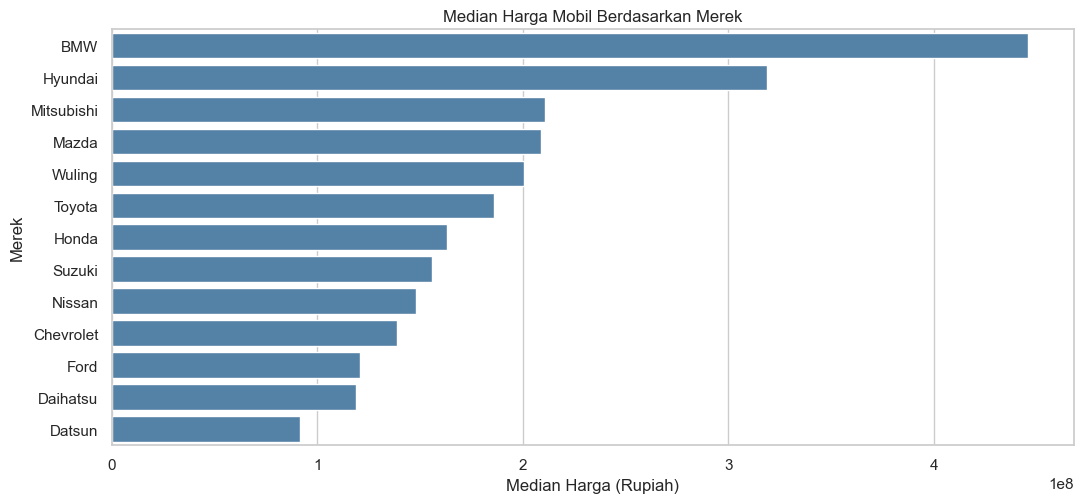

In [17]:
brand_analysis = df[["brand"]].copy()
brand_analysis["price"] = price
brand_analysis = brand_analysis.dropna(subset=["brand", "price"])

brand_summary = (
    brand_analysis.groupby("brand")["price"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .sort_values("median", ascending=False)
)

display(brand_summary)

brand_plot_data = brand_summary.reset_index()

plt.figure(figsize=(11, max(5, 0.4 * len(brand_plot_data))))
sns.barplot(
    data=brand_plot_data,
    y="brand",
    x="median",
    color="steelblue"
)
plt.title("Median Harga Mobil Berdasarkan Merek")
plt.xlabel("Median Harga (Rupiah)")
plt.ylabel("Merek")
plt.tight_layout()
plt.show()


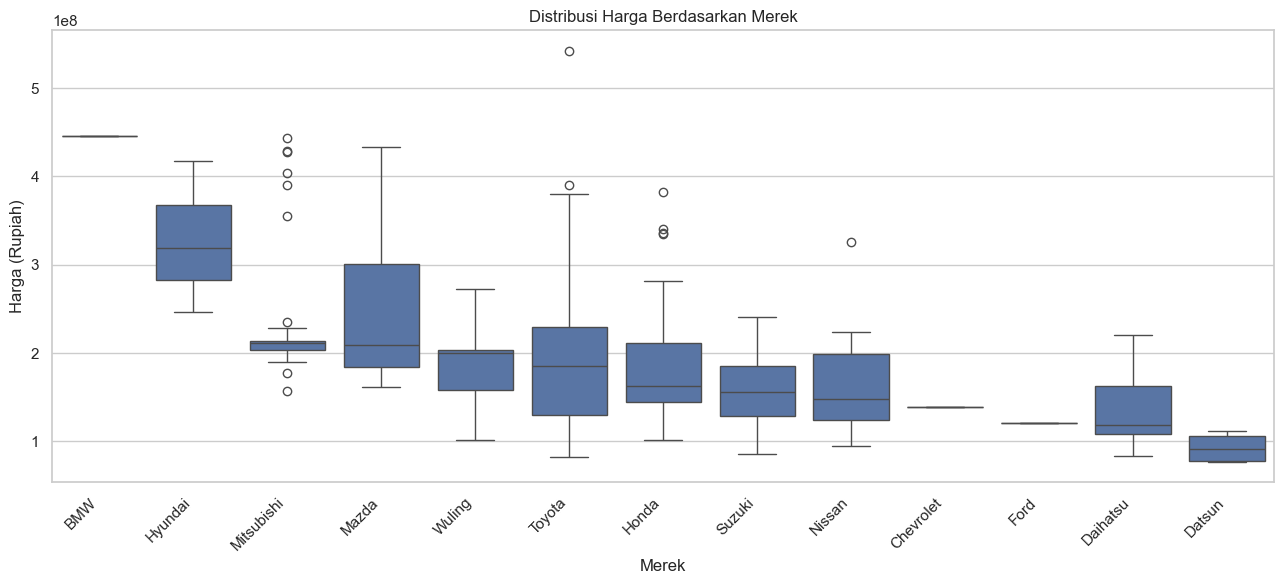

In [18]:
brand_order = brand_summary.index.tolist()

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=brand_analysis,
    x="brand",
    y="price",
    order=brand_order
)
plt.title("Distribusi Harga Berdasarkan Merek")
plt.xlabel("Merek")
plt.ylabel("Harga (Rupiah)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Analisis Harga Berdasarkan Transmisi

Bandingkan jumlah observasi, rata-rata, median, dan sebaran harga per kategori transmisi. Hasil ini bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat.


,jumlah,rata_rata,median,minimum,maksimum
transmission,,,,,
Automatic,446,"200,524,663.68","197,000,000.00",86000000,542000000
Manual,163,"134,966,257.67","122,000,000.00",77000000,256000000


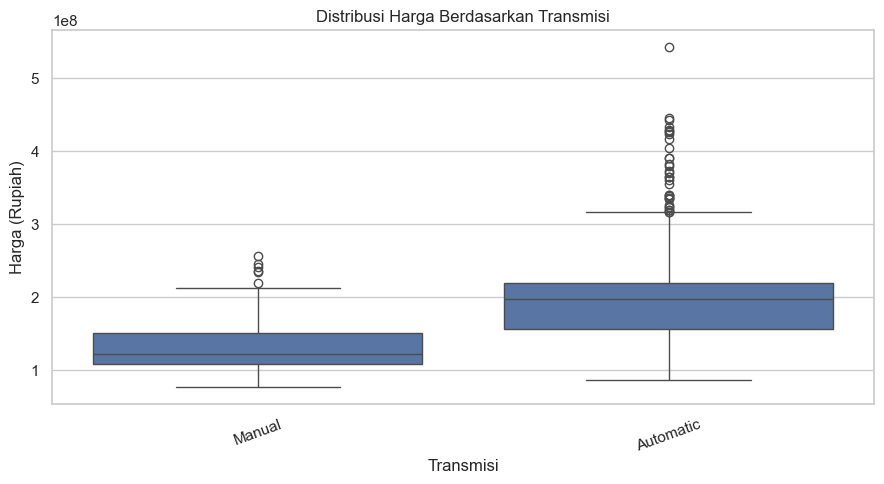

In [19]:
transmission_analysis = df[["transmission"]].copy()
transmission_analysis["price"] = price
transmission_analysis = transmission_analysis.dropna(subset=["transmission", "price"])

transmission_summary = (
    transmission_analysis.groupby("transmission")["price"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .sort_values("median", ascending=False)
)

display(transmission_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=transmission_analysis,
    x="transmission",
    y="price"
)
plt.title("Distribusi Harga Berdasarkan Transmisi")
plt.xlabel("Transmisi")
plt.ylabel("Harga (Rupiah)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 9. Hubungan Tahun Produksi dengan Harga

Scatterplot digunakan untuk mengamati pola hubungan tahun produksi dan harga. Korelasi dihitung menggunakan Pearson dan Spearman sebagai ukuran asosiasi, bukan bukti kausalitas.


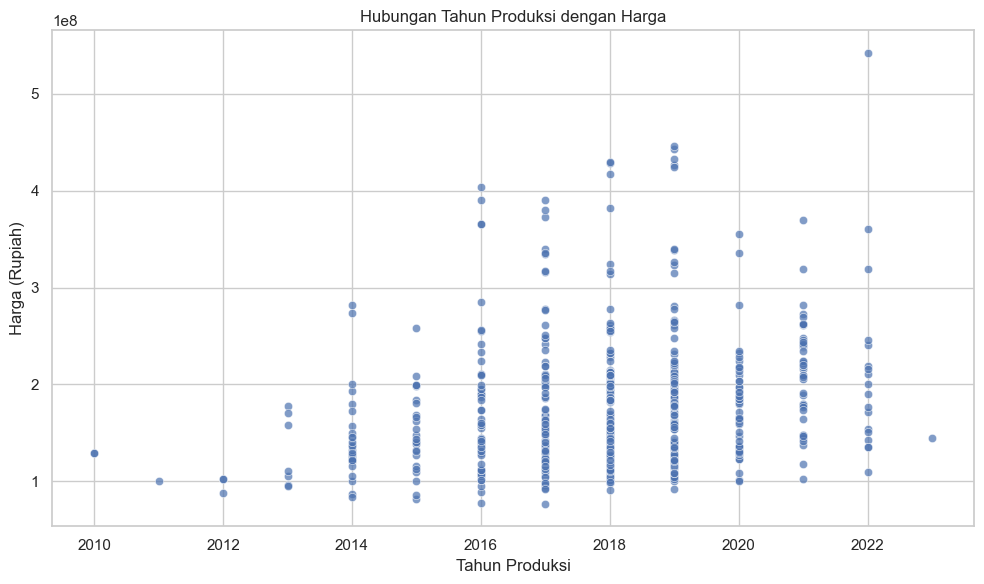

Korelasi Pearson : 0.23054022728401677
Korelasi Spearman: 0.2514172472348229


In [20]:
year_price = pd.DataFrame({
    "year": year,
    "price": price
}).dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=year_price, x="year", y="price", alpha=0.7)
plt.title("Hubungan Tahun Produksi dengan Harga")
plt.xlabel("Tahun Produksi")
plt.ylabel("Harga (Rupiah)")
plt.tight_layout()
plt.show()

if len(year_price) >= 2:
    print("Korelasi Pearson :", year_price["year"].corr(year_price["price"], method="pearson"))
    print("Korelasi Spearman:", year_price["year"].corr(year_price["price"], method="spearman"))
else:
    print("Data valid tidak cukup untuk menghitung korelasi.")


## 10. Hubungan Mileage dengan Harga

Interpretasi hubungan mileage dengan harga harus mempertimbangkan bahwa format dan satuan mileage masih perlu diverifikasi.


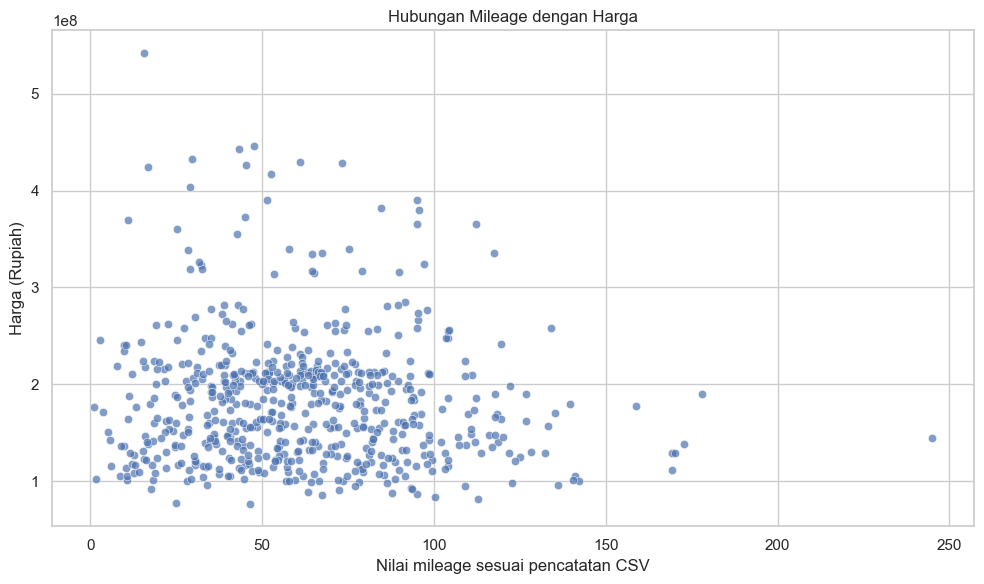

Korelasi Pearson : -0.07714645476341282
Korelasi Spearman: -0.04899329567978148


In [21]:
mileage_price = pd.DataFrame({
    "mileage": mileage,
    "price": price
}).dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=mileage_price, x="mileage", y="price", alpha=0.7)
plt.title("Hubungan Mileage dengan Harga")
plt.xlabel("Nilai mileage sesuai pencatatan CSV")
plt.ylabel("Harga (Rupiah)")
plt.tight_layout()
plt.show()

if len(mileage_price) >= 2:
    print("Korelasi Pearson :", mileage_price["mileage"].corr(mileage_price["price"], method="pearson"))
    print("Korelasi Spearman:", mileage_price["mileage"].corr(mileage_price["price"], method="spearman"))
else:
    print("Data valid tidak cukup untuk menghitung korelasi.")


## 11. Analisis Fitur Biner terhadap Harga

Fitur biner yang ditemukan akan diperiksa nilai uniknya terlebih dahulu. Ringkasan membandingkan jumlah observasi dan median harga untuk nilai 0 dan 1. Kategori yang tidak memiliki nilai 0/1 akan ditandai dan tidak dipaksakan ke analisis biner.


In [22]:
binary_features = [
    "rear camera",
    "sun roof",
    "auto retract mirror",
    "electric parking brake",
    "map navigator",
    "vehicle stability control",
    "keyless push start",
    "sports mode",
    "360 camera view",
    "power sliding door",
    "auto cruise control"
]

available_binary_features = [
    column for column in binary_features if column in df.columns
]

binary_rows = []
valid_binary_features = []

for column in available_binary_features:
    values = pd.to_numeric(df[column], errors="coerce")
    observed_values = set(values.dropna().unique())

    if observed_values.issubset({0, 1}) and len(observed_values) > 0:
        valid_binary_features.append(column)
        for value in [0, 1]:
            mask = values.eq(value)
            binary_rows.append({
                "fitur": column,
                "nilai": value,
                "jumlah": int(mask.sum()),
                "median_harga": price[mask].median()
            })
    else:
        print(f"Perlu diperiksa, bukan biner 0/1: {column}; nilai unik={sorted(observed_values, key=str)}")

binary_summary = pd.DataFrame(binary_rows)
display(binary_summary)


,fitur,nilai,jumlah,median_harga
0,rear camera,0,522,"174,000,000.00"
1,rear camera,1,87,"183,000,000.00"
2,sun roof,0,591,"172,000,000.00"
3,sun roof,1,18,"227,500,000.00"
4,auto retract mirror,0,323,"140,000,000.00"
5,auto retract mirror,1,286,"208,000,000.00"
6,electric parking brake,0,590,"172,000,000.00"
7,electric parking brake,1,19,"248,000,000.00"
8,map navigator,0,603,"176,000,000.00"
9,map navigator,1,6,"190,000,000.00"


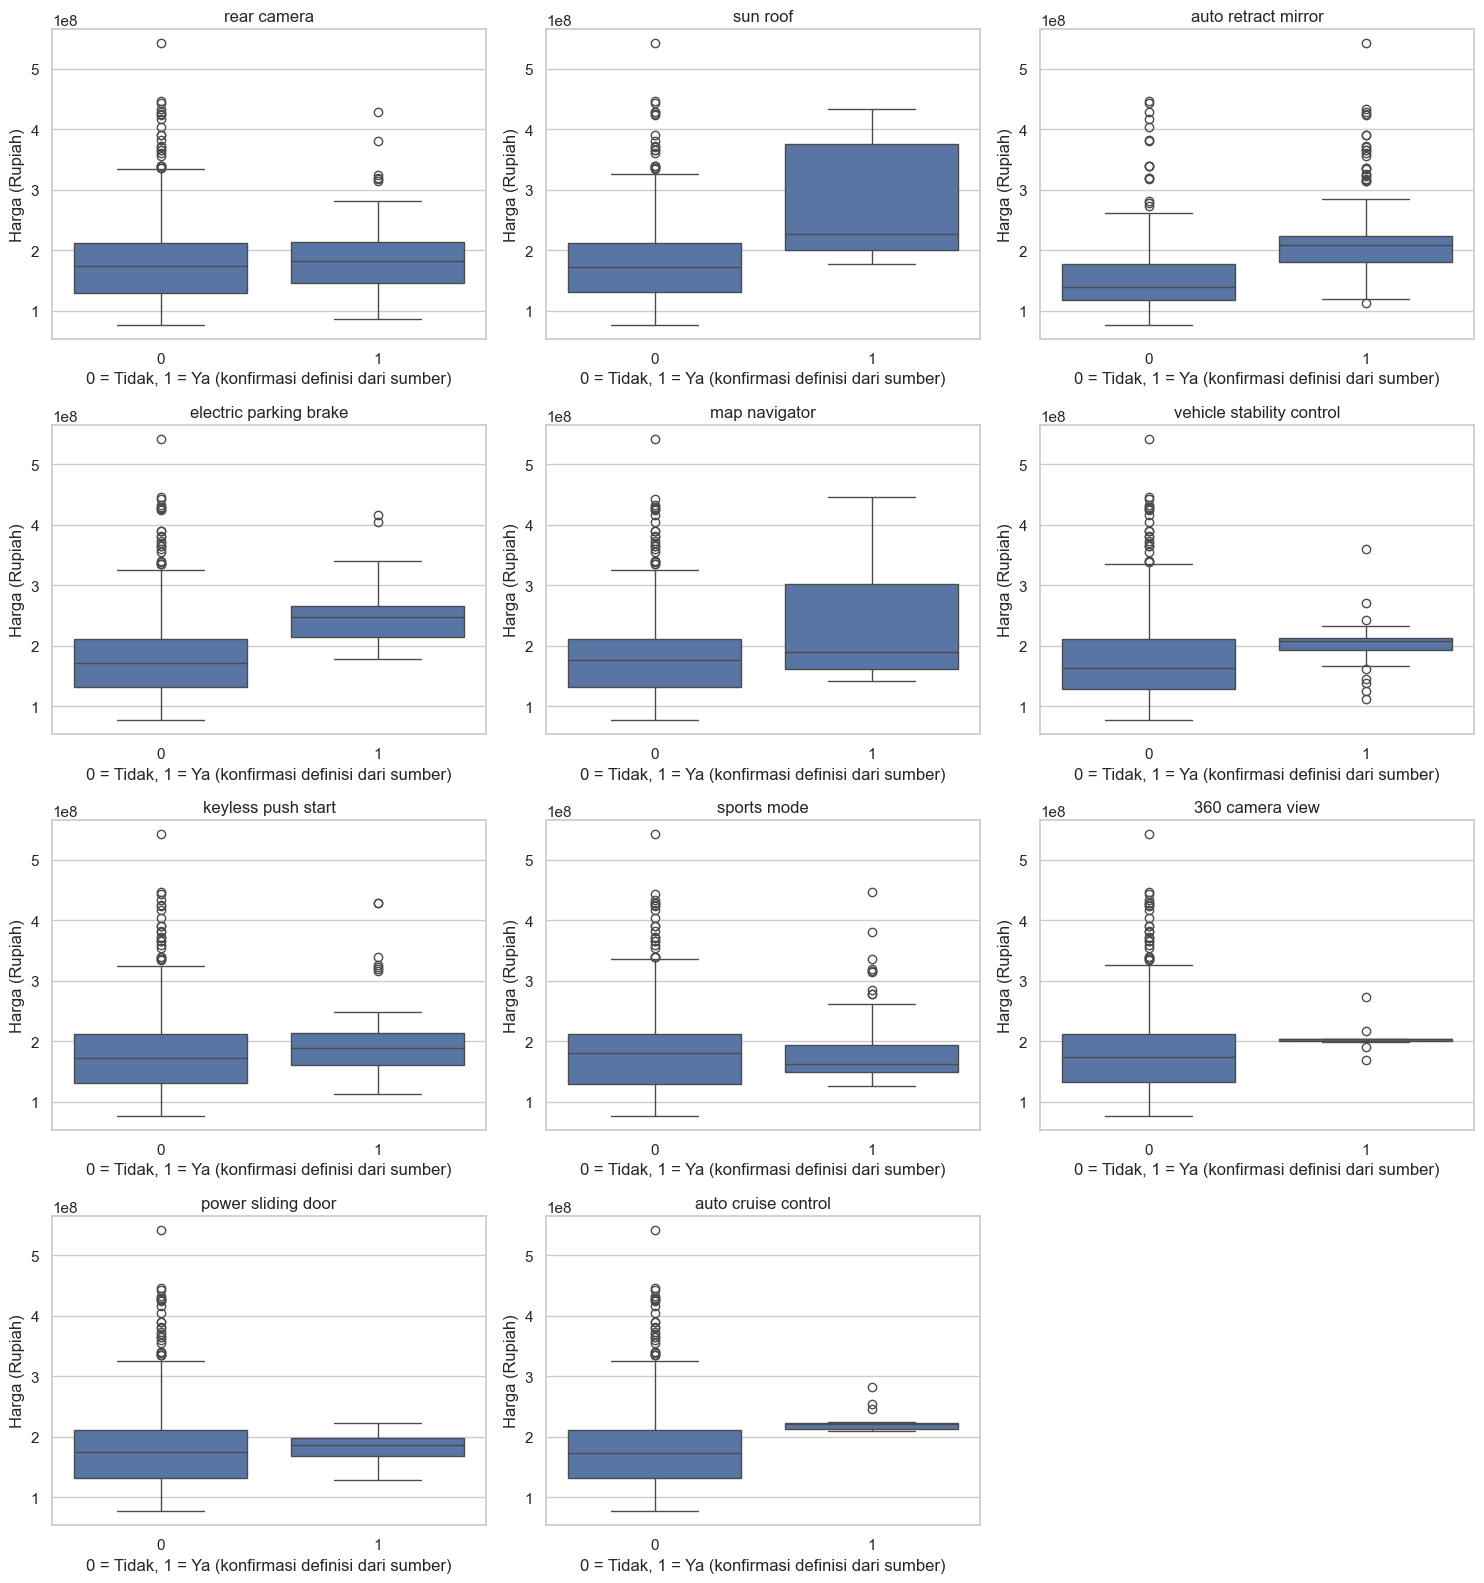

In [23]:
if valid_binary_features:
    n_features = len(valid_binary_features)
    n_cols = 3
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 4 * n_rows),
        squeeze=False
    )

    for index, column in enumerate(valid_binary_features):
        row, col = divmod(index, n_cols)
        plot_data = pd.DataFrame({
            "status": pd.to_numeric(df[column], errors="coerce"),
            "price": price
        }).dropna()

        sns.boxplot(data=plot_data, x="status", y="price", ax=axes[row, col])
        axes[row, col].set_title(column)
        axes[row, col].set_xlabel("0 = Tidak, 1 = Ya (konfirmasi definisi dari sumber)")
        axes[row, col].set_ylabel("Harga (Rupiah)")

    for index in range(n_features, n_rows * n_cols):
        row, col = divmod(index, n_cols)
        axes[row, col].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan fitur yang terverifikasi sebagai biner 0/1.")


## 12. Analisis Korelasi

Korelasi Pearson dan Spearman dihitung pada kolom numerik. Variabel cicilan tetap ditampilkan untuk audit hubungan dengan target, tetapi harus diperlakukan sebagai kandidat data leakage dan bukan otomatis sebagai fitur prediktor.


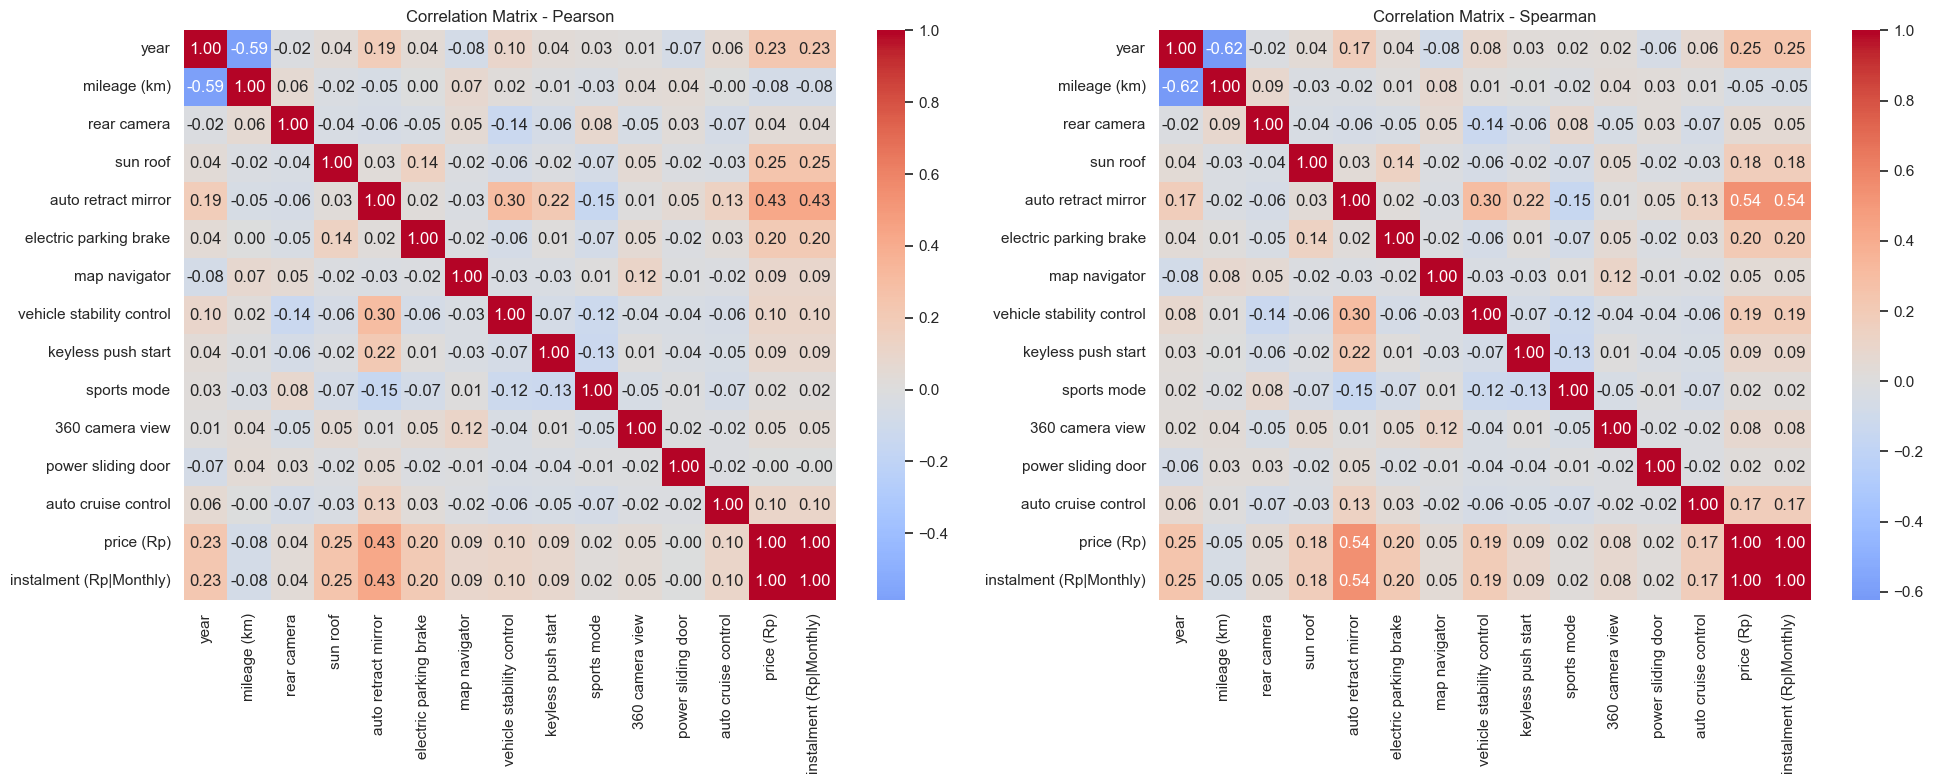

In [24]:
numeric_df = df.select_dtypes(include="number").copy()

if TARGET not in numeric_df.columns:
    numeric_df[TARGET] = price

pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    pearson_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Correlation Matrix - Pearson")

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Correlation Matrix - Spearman")

plt.tight_layout()
plt.show()


In [25]:
if TARGET in pearson_corr.columns:
    target_corr = pd.DataFrame({
        "pearson": pearson_corr[TARGET],
        "spearman": spearman_corr[TARGET]
    }).drop(index=TARGET, errors="ignore")

    display(target_corr.sort_values("pearson", key=lambda series: series.abs(), ascending=False))

    if "instalment (Rp|Monthly)" in target_corr.index:
        print(
            "PERHATIAN: korelasi cicilan dengan harga =",
            target_corr.loc["instalment (Rp|Monthly)", "pearson"],
            ". Evaluasi sebagai potensi data leakage; jangan otomatis dipakai sebagai fitur."
        )


,pearson,spearman
instalment (Rp|Monthly),1.00,1.00
auto retract mirror,0.43,0.54
sun roof,0.25,0.18
year,0.23,0.25
electric parking brake,0.20,0.20
auto cruise control,0.10,0.17
vehicle stability control,0.10,0.19
map navigator,0.09,0.05
keyless push start,0.09,0.09
mileage (km),-0.08,-0.05


PERHATIAN: korelasi cicilan dengan harga = 0.9999979190615439 . Evaluasi sebagai potensi data leakage; jangan otomatis dipakai sebagai fitur.


## 13. Ringkasan Insight EDA

Berdasarkan hasil analisis yang telah tersedia, berikut tiga insight awal yang dapat dipertanggungjawabkan. Insight ini menggunakan hasil histogram, boxplot, statistik deskriptif, perhitungan IQR, dan pemeriksaan korelasi yang telah dilakukan sebelumnya.

### Insight 1. Distribusi harga mobil bekas cenderung menceng ke kanan (*positively skewed*)

**Temuan:** Distribusi harga mobil bekas tidak simetris dan menunjukkan kemencengan ke kanan.

**Bukti:** Nilai skewness harga sekitar **1,452**. Median harga sekitar **Rp177.000.000**, dengan kuartil pertama (Q1) sekitar **Rp132.000.000** dan kuartil ketiga (Q3) sekitar **Rp212.000.000**. Histogram menunjukkan sebagian besar observasi terkonsentrasi pada kisaran kurang lebih **Rp100 juta hingga Rp230 juta**, sedangkan terdapat sejumlah kecil mobil dengan harga jauh lebih tinggi, hingga sekitar **Rp542 juta**.

**Interpretasi:** Sebagian besar mobil dalam dataset berada pada kelompok harga menengah, sementara sebagian kecil kendaraan memiliki harga relatif tinggi. Ekor distribusi yang memanjang ke kanan menyebabkan distribusi harga tidak simetris.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Perlu dilakukan pemeriksaan lebih lanjut terhadap harga yang sangat tinggi untuk memastikan bahwa nilai tersebut merupakan harga kendaraan yang valid, bukan kesalahan pencatatan. Kemencengan distribusi juga perlu dipertimbangkan ketika mengevaluasi kebutuhan transformasi target.

**Implikasi terhadap Feature Selection/Modeling:** Evaluasi performa model perlu memperhatikan kemungkinan pengaruh observasi berharga tinggi terhadap kesalahan prediksi. Transformasi logaritmik terhadap target dapat diuji sebagai eksperimen, tetapi tidak boleh diterapkan tanpa membandingkan performa model sebelum dan sesudah transformasi.

### Insight 2. Terdapat observasi harga yang terindikasi sebagai outlier berdasarkan metode IQR

**Temuan:** Sebagian observasi memiliki harga yang berada di luar batas atas IQR.

**Bukti:** Dengan Q1 sekitar **Rp132.000.000** dan Q3 sekitar **Rp212.000.000**, diperoleh IQR sekitar **Rp80.000.000**. Batas atas IQR adalah sekitar **Rp332.000.000**. Pemeriksaan awal menandai **26 observasi** sebagai outlier harga dari total **609 observasi**, atau sekitar **4,27%**.

**Interpretasi:** Sebagian kecil kendaraan memiliki harga yang jauh lebih tinggi dibandingkan rentang tengah distribusi harga. Status outlier berdasarkan IQR hanya menunjukkan posisi nilai yang ekstrem secara statistik, bukan membuktikan bahwa data tersebut salah.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Seluruh observasi yang terindikasi perlu diperiksa berdasarkan informasi kendaraan, seperti merek, model, tahun produksi, dan fitur kendaraan. Observasi yang valid harus dipertahankan. Penghapusan atau pembatasan nilai hanya dapat dilakukan jika ditemukan alasan yang kuat dan terdokumentasi.

**Implikasi terhadap Feature Selection/Modeling:** Model berbasis pohon dan model regresi linear dapat merespons observasi ekstrem secara berbeda. Karena itu, evaluasi model sebaiknya membandingkan metrik dan residual, serta menguji strategi penanganan outlier hanya jika didukung hasil audit.

### Insight 3. Variabel cicilan memiliki hubungan yang hampir sempurna dengan harga dan berpotensi menyebabkan data leakage

**Temuan:** Variabel `instalment (Rp|Monthly)` memiliki korelasi yang hampir sempurna dengan variabel target `price (Rp)`.

**Bukti:** Pemeriksaan korelasi sebelumnya menunjukkan nilai korelasi sekitar **0,999998** antara cicilan bulanan dan harga mobil.

**Interpretasi:** Hubungan yang hampir sempurna tersebut mengindikasikan bahwa nilai cicilan mungkin dihitung atau dibentuk secara langsung dari harga kendaraan. Jika variabel cicilan digunakan untuk memprediksi harga, model berisiko memperoleh informasi yang secara praktis sudah merepresentasikan target.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Asal-usul, rumus pembentukan, dan waktu ketersediaan variabel cicilan perlu diperiksa. Korelasi tinggi merupakan indikasi yang perlu ditelusuri, tetapi belum menjadi bukti tunggal bahwa data leakage pasti terjadi.

**Implikasi terhadap Feature Selection/Modeling:** Untuk pemodelan prediksi harga berdasarkan karakteristik kendaraan, `instalment (Rp|Monthly)` sebaiknya **tidak digunakan sebagai fitur prediktor pada eksperimen awal**. Variabel ini dapat dikeluarkan dari kandidat fitur agar evaluasi model tidak menghasilkan performa yang tampak sangat tinggi akibat kebocoran informasi target.

---

### Catatan batasan interpretasi

Tiga insight di atas merupakan insight awal berdasarkan hasil yang sudah tersedia. Insight tambahan mengenai mileage, perbedaan harga antarmerek, transmisi, serta hubungan tahun produksi dengan harga harus ditulis setelah output analisis terkait dijalankan dan diperiksa. Jangan mengisi temuan tersebut dengan asumsi.

### Ringkasan implikasi

| No. | Insight | Tindak lanjut |
|---|---|---|
| 1 | Distribusi harga menceng ke kanan | Evaluasi transformasi target dan residual model |
| 2 | 26 observasi harga terindikasi outlier IQR | Periksa validitas setiap observasi sebelum menentukan penanganan |
| 3 | Korelasi cicilan dan harga sekitar 0,999998 | Keluarkan cicilan dari fitur prediktor awal dan telusuri potensi data leakage |

